In [1]:
# .3.2 תהליך ניתוח הנתונים 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
bl = pd.read_csv('‏‏bank_loan_updated.csv')

In [3]:
bl

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,MonthlyPayment,CreditScore,StartDate,EndDate
0,Yael Friedman,99420880,133,VIP,Female,14/11/1982,Netanya,Roni Malka,7439,4770.0,277.552,621.0,09/12/2024,09/08/2028
1,Daniel Cohen,18065024,241,Business,Male,22/03/1975,Tel Aviv,Eyal Green,4966,3485.0,148.356,836.0,03/06/2024,03/03/2029
2,Yossi Peretz,55180378,154,Retail,Male,08/07/1991,Haifa,Shani Levi,8075,1836.0,291.771,720.0,11/05/2024,11/03/2027
3,Tamar Barak,71324371,104,Business,Female,19/01/1987,Haifa,Lior Ben Ami,16331,3305.0,979.869,580.0,07/03/2025,07/11/2026
4,Noa Mizrahi,44562073,119,Private,Female,03/09/1996,Ramat Gan,Tomer Azulay,10754,3044.0,287.482,639.0,23/04/2025,23/04/2029
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,Tamar Barak,65092800,104,Business,Female,03/09/1971,Beer Sheva,Lior Ben Ami,10076,3345.0,1034.266,762.0,21/04/2024,21/05/2025
116,Yossi Peretz,33627104,119,Private,Male,11/02/1990,Netanya,Tomer Azulay,4234,4830.0,312.467,765.0,13/03/2024,13/08/2026
117,Niv Sharon,47967315,241,Business,Male,30/08/1986,Ashdod,Eyal Green,16794,2651.0,1215.412,741.0,03/03/2025,03/07/2026
118,Maya Levi,39276583,133,VIP,Female,19/06/1974,Haifa,Roni Malka,4364,NaN,163.370,575.0,18/06/2025,18/02/2030


In [4]:
bl.info ()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ClientName      120 non-null    str    
 1   Account         120 non-null    int64  
 2   Branch          120 non-null    int64  
 3   BankingType     120 non-null    str    
 4   Gender          120 non-null    str    
 5   BirthDate       114 non-null    str    
 6   City            117 non-null    str    
 7   BankerName      120 non-null    str    
 8   Principal       120 non-null    int64  
 9   Interest        117 non-null    float64
 10  MonthlyPayment  117 non-null    float64
 11  CreditScore     117 non-null    float64
 12  StartDate       120 non-null    str    
 13  EndDate         120 non-null    str    
dtypes: float64(3), int64(3), str(8)
memory usage: 13.3 KB


In [5]:
bl.shape

(120, 14)

In [6]:
# .3.3 טיפול בנתונים
bl.isnull().sum()

ClientName        0
Account           0
Branch            0
BankingType       0
Gender            0
BirthDate         6
City              3
BankerName        0
Principal         0
Interest          3
MonthlyPayment    3
CreditScore       3
StartDate         0
EndDate           0
dtype: int64

In [7]:
#אמיר את הדאטאטייפ של העמודות עם התאריכים שמוצגות כסטרינג:
bl['BirthDate']=bl['BirthDate'].astype('datetime64[ns]')
bl['StartDate']=bl['StartDate'].astype('datetime64[ns]')
bl['EndDate']=bl['EndDate'].astype('datetime64[ns]')

In [8]:
#אמיר את עמודת מספר חשבון ומספר סניף כסטרינג כי אין להם משמעות מספרית.
bl['Account']=bl['Account'].astype(str)
bl['Branch']=bl['Branch'].astype(str)

In [9]:
bl.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ClientName      120 non-null    str           
 1   Account         120 non-null    str           
 2   Branch          120 non-null    str           
 3   BankingType     120 non-null    str           
 4   Gender          120 non-null    str           
 5   BirthDate       114 non-null    datetime64[ns]
 6   City            117 non-null    str           
 7   BankerName      120 non-null    str           
 8   Principal       120 non-null    int64         
 9   Interest        117 non-null    float64       
 10  MonthlyPayment  117 non-null    float64       
 11  CreditScore     117 non-null    float64       
 12  StartDate       120 non-null    datetime64[ns]
 13  EndDate         120 non-null    datetime64[ns]
dtypes: datetime64[ns](3), float64(3), int64(1), str(7)
memory usage: 13.3

In [10]:
bl['Age']=((bl['StartDate']-bl['BirthDate']).dt.days / 365).round(1)
bl['LoanDurationMonths']=((bl['EndDate']-bl['StartDate']).dt.days/ 30).round(2)
bl['TotalPayment']=(bl['MonthlyPayment']* bl['LoanDurationMonths']).round(2)
bl['StartYear']=bl['StartDate'].dt.year

In [11]:
bl.head(5)

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,MonthlyPayment,CreditScore,StartDate,EndDate,Age,LoanDurationMonths,TotalPayment,StartYear
0,Yael Friedman,99420880,133,VIP,Female,1982-11-14,Netanya,Roni Malka,7439,4770.0,277.552,621.0,2024-09-12,2028-09-08,41.9,48.57,13480.70,2024
1,Daniel Cohen,18065024,241,Business,Male,1975-03-22,Tel Aviv,Eyal Green,4966,3485.0,148.356,836.0,2024-03-06,2029-03-03,49.0,60.77,9015.59,2024
2,Yossi Peretz,55180378,154,Retail,Male,1991-08-07,Haifa,Shani Levi,8075,1836.0,291.771,720.0,2024-11-05,2027-11-03,33.3,36.43,10629.22,2024
3,Tamar Barak,71324371,104,Business,Female,1987-01-19,Haifa,Lior Ben Ami,16331,3305.0,979.869,580.0,2025-07-03,2026-07-11,38.5,12.43,12179.77,2025
4,Noa Mizrahi,44562073,119,Private,Female,1996-03-09,Ramat Gan,Tomer Azulay,10754,3044.0,287.482,639.0,2025-04-23,2029-04-23,29.1,48.70,14000.37,2025


In [12]:
# השלמת ערכים חסרים
#החלטתי להשלים את הערכים המספריים בחציון כי כך הם פחות מושפעים מערכים קיצוניים (לכן לא בחרתי ממוצע)
#לא השלמתי את עמודת BirthDate בגלל שהיא בדאטאטייפ של תאריך.
bl['City']=bl['City'].fillna('Unknown')
bl['Interest']=bl['Interest'].fillna(bl['Interest'].median())
bl['MonthlyPayment']=bl['MonthlyPayment'].fillna(bl['MonthlyPayment'].median())
bl['CreditScore']=bl['CreditScore'].fillna(bl['CreditScore'].median())
bl['Age']=bl['Age'].fillna(bl['Age'].median())
bl['TotalPayment']=bl['TotalPayment'].fillna(bl['TotalPayment'].median())

In [13]:
#בדיקה שוב
bl.isnull().sum()

ClientName            0
Account               0
Branch                0
BankingType           0
Gender                0
BirthDate             6
City                  0
BankerName            0
Principal             0
Interest              0
MonthlyPayment        0
CreditScore           0
StartDate             0
EndDate               0
Age                   0
LoanDurationMonths    0
TotalPayment          0
StartYear             0
dtype: int64

In [14]:
#ייבאתי דוגמא של נתונים כדי לראות שהכל הושלם כמו שצריך
bl.iloc[50:60]

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,MonthlyPayment,CreditScore,StartDate,EndDate,Age,LoanDurationMonths,TotalPayment,StartYear
50,Omer Klein,10725864,104,Business,Male,1979-05-04,Haifa,Lior Ben Ami,6792,3513.0,427.494,566.0,2025-05-21,2027-04-21,46.10,23.33,14080.18,2025
51,Eitan Mor,57638871,221,VIP,Female,1985-03-09,Ramat Gan,Maya Levi,13072,2412.0,1713.938,721.0,2025-03-31,2025-12-31,40.10,9.17,15716.81,2025
52,Noa Mizrahi,33999014,154,VIP,Female,1997-08-30,Ramat Gan,Dana Cohen,15875,3422.0,644.080,687.0,2024-12-18,2027-06-18,27.30,30.40,19580.03,2024
53,Yossi Peretz,38938599,180,Retail,Male,NaT,Herzliya,Noa Dayan,2601,1789.0,230.797,606.0,2025-05-24,2026-12-24,40.45,19.30,4454.38,2025
54,Daniel Cohen,50348883,221,VIP,Male,1977-11-14,Jerusalem,Maya Levi,10578,3613.0,258.203,582.0,2025-07-02,2029-07-09,47.70,48.93,12633.87,2025
55,Yael Friedman,56094751,180,Retail,Female,1994-12-16,Unknown,Noa Dayan,14716,225.0,1067.615,699.0,2025-04-27,2026-06-27,30.40,14.20,15160.13,2025
56,Omer Klein,18921522,154,VIP,Female,1981-11-02,Haifa,Dana Cohen,17087,2076.0,617.926,697.0,2024-06-16,2027-01-16,42.60,31.47,19446.13,2024
57,Lior Ben David,88099593,119,Private,Male,1973-05-27,Jerusalem,Tomer Azulay,3981,4645.0,148.852,752.0,2025-02-23,2029-12-23,51.80,58.80,8752.50,2025
58,Lior Ben David,49898058,154,Retail,Female,1998-08-07,Jerusalem,Shani Levi,9557,3208.0,1815.732,848.0,2025-08-06,2026-08-01,27.00,12.00,21788.78,2025
59,Yael Friedman,93510429,112,Private,Male,1966-05-04,Beer Sheva,Daniel Bar,16483,3776.0,810.360,804.0,2024-12-05,2026-12-06,58.60,24.37,19748.47,2024


In [15]:
#בדיקת ערכים חריגים
import pandasql as pds

pds.sqldf("""SELECT *
             FROM bl
             WHERE Age NOT BETWEEN 24 AND 61
                OR Principal <0
                OR Interest <0
                OR MonthlyPayment <=0
                OR CreditScore NOT BETWEEN 300 AND 850""", globals())

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,MonthlyPayment,CreditScore,StartDate,EndDate,Age,LoanDurationMonths,TotalPayment,StartYear


In [16]:
# .3.4 + .3.5 ניתוח סטטיסטי תיאורי וניתוח מתקדם 
# סטטיסטיקה תיאורית עבור המשתנים המספריים הרלוונטים
bl[['Principal','Interest','MonthlyPayment','CreditScore','Age','LoanDurationMonths','TotalPayment']].describe()

,Principal,Interest,MonthlyPayment,CreditScore,Age,LoanDurationMonths,TotalPayment
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.00000
mean,11186.300000,2761.258333,622.924775,701.000000,41.239167,32.249333,14059.40875
std,5348.477441,1352.941573,561.895582,85.564266,9.848461,16.124956,6205.71206
min,2006.000000,225.000000,112.915000,557.000000,25.100000,0.270000,618.50000
25%,5891.000000,1831.500000,247.729500,627.000000,32.550000,20.027500,9171.80250
50%,11309.000000,2674.000000,427.494000,699.000000,40.450000,30.400000,14080.18000
75%,16153.500000,3841.000000,780.720500,768.750000,50.000000,48.647500,18883.06000
max,19970.000000,4989.000000,3155.056000,849.000000,60.700000,60.870000,32725.00000


In [17]:
# ניתוח לפי סוג הבנקאות:
bl.groupby('BankingType')[['Principal', 'Interest', 'MonthlyPayment', 'CreditScore']].mean().round(2)

,Principal,Interest,MonthlyPayment,CreditScore
BankingType,,,,
Business,11019.27,2488.93,620.78,699.93
Private,10317.47,2864.79,489.19,712.74
Retail,10686.40,2635.93,728.91,706.87
VIP,13092.00,3084.69,678.01,680.12


In [18]:
#ניתוח לפי מגדר:
bl.groupby('Gender')[['Principal', 'Interest', 'MonthlyPayment', 'CreditScore']].mean().round(2)

,Principal,Interest,MonthlyPayment,CreditScore
Gender,,,,
Female,12007.94,2764.80,665.14,699.55
Male,10579.00,2758.64,591.72,702.07


In [19]:
# יצירת קבוצות דירוג אשראי
def CreditCategory(score):
    if score<650:
        return "Low"
    elif score<750:
        return "Medium"
    else:
        return "High"

In [20]:
bl['CreditCategory']=bl['CreditScore'].apply(CreditCategory)

In [21]:
# אראה כמה יש בכל קבוצת דירוג אשראי:
bl['CreditCategory'].value_counts()

CreditCategory
Medium    41
High      40
Low       39
Name: count, dtype: int64

In [22]:
# יצירת קבוצות גילאי לקוחות
def AgeCategory(age):
    if age<=33:
        return "Young"
    elif age<=43:
        return "Young Adult"
    elif age<=53:
        return "Adult"
    else:
        return "Mature"

In [23]:
bl['AgeCategory']=bl['Age'].apply(AgeCategory)

In [24]:
# אראה כמה יש בכל קבוצת גילאים:
bl['AgeCategory'].value_counts()

AgeCategory
Young Adult    40
Young          32
Adult          29
Mature         19
Name: count, dtype: int64

In [25]:
#בדיקה שהכל תקין
bl.head(10)

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,MonthlyPayment,CreditScore,StartDate,EndDate,Age,LoanDurationMonths,TotalPayment,StartYear,CreditCategory,AgeCategory
0,Yael Friedman,99420880,133,VIP,Female,1982-11-14,Netanya,Roni Malka,7439,4770.0,277.552,621.0,2024-09-12,2028-09-08,41.90,48.57,13480.70,2024,Low,Young Adult
1,Daniel Cohen,18065024,241,Business,Male,1975-03-22,Tel Aviv,Eyal Green,4966,3485.0,148.356,836.0,2024-03-06,2029-03-03,49.00,60.77,9015.59,2024,High,Adult
2,Yossi Peretz,55180378,154,Retail,Male,1991-08-07,Haifa,Shani Levi,8075,1836.0,291.771,720.0,2024-11-05,2027-11-03,33.30,36.43,10629.22,2024,Medium,Young Adult
3,Tamar Barak,71324371,104,Business,Female,1987-01-19,Haifa,Lior Ben Ami,16331,3305.0,979.869,580.0,2025-07-03,2026-07-11,38.50,12.43,12179.77,2025,Low,Young Adult
4,Noa Mizrahi,44562073,119,Private,Female,1996-03-09,Ramat Gan,Tomer Azulay,10754,3044.0,287.482,639.0,2025-04-23,2029-04-23,29.10,48.70,14000.37,2025,Low,Young
5,Yael Friedman,36191763,103,Private,Female,NaT,Ashdod,Yael Mizrahi,16045,3762.0,1526.393,791.0,2024-09-06,2025-09-07,40.45,12.20,18621.99,2024,High,Young Adult
6,Yael Friedman,96063796,241,Business,Female,1970-11-14,Tel Aviv,Eyal Green,16320,2674.0,661.868,718.0,2024-07-04,2026-07-06,53.70,24.40,16149.58,2024,Medium,Mature
7,Yael Friedman,18968851,154,VIP,Female,NaT,Haifa,Dana Cohen,11461,3259.0,334.386,600.0,2025-04-22,2028-12-22,40.45,44.67,14937.02,2025,Low,Young Adult
8,Lior Ben David,85635723,112,Private,Male,1984-05-27,Ramat Gan,Daniel Bar,17863,936.0,783.893,591.0,2024-04-29,2026-04-29,40.00,24.33,19072.12,2024,Low,Young Adult
9,Shira Azulay,80978782,154,VIP,Female,1993-11-02,Unknown,Dana Cohen,18924,256.0,685.257,585.0,2024-08-25,2026-12-25,30.80,28.40,19461.30,2024,Low,Young


In [26]:
#קיבוץ באמצעות aggregation
#לפי סוג הבנקאות 
agg_banking=bl.groupby('BankingType')[['Principal','Interest','MonthlyPayment','CreditScore','Age']].agg(['count','mean','median','std']).round(2)
agg_banking

Principal                             Interest                   \
                count      mean   median      std    count     mean  median   
BankingType                                                                   
Business           30  11019.27  10471.0  5122.96       30  2488.93  2497.0   
Private            34  10317.47  10349.0  5607.45       34  2864.79  3039.0   
Retail             30  10686.40  11394.0  5219.31       30  2635.93  2595.0   
VIP                26  13092.00  14420.0  5242.09       26  3084.69  2955.0   

                     MonthlyPayment                         CreditScore  \
                 std          count    mean  median     std       count   
BankingType                                                               
Business     1446.07             30  620.78  424.69  592.19          30   
Private      1310.48             34  489.19  381.17  380.53          34   
Retail       1373.61             30  728.91  473.05  695.79          30   
VIP          1265.09             26  678.01  577.81  549.89          26   

                                    Age                       
               mean median    std count   mean median    std  
BankingType                                                   
Business     699.93  690.0  96.00    30  41.28  38.50   9.20  
Private      712.74  710.5  80.08    34  41.51  40.58   9.83  
Retail       706.87  716.5  80.60    30  41.98  40.48  10.61  
VIP          680.12  679.0  86.44    26  39.97  40.28  10.15

In [27]:
#לפי קבוצת דירוג אשראי
agg_credit=bl.groupby('CreditCategory')[['Principal','Interest','MonthlyPayment','CreditScore']].agg(['count','mean','median','std']).round(2)
agg_credit

Principal                             Interest           \
                   count      mean   median      std    count     mean   
CreditCategory                                                           
High                  40  11771.58  13341.0  5510.82       40  2865.58   
Low                   39  11268.28  10754.0  5255.37       39  2819.46   
Medium                41  10537.32  12471.0  5336.18       41  2604.12   

                                MonthlyPayment                          \
                median      std          count    mean  median     std   
CreditCategory                                                           
High            3003.5  1272.54             40  759.72  452.81  700.16   
Low             3044.0  1369.85             39  531.83  421.89  463.63   
Medium          2512.0  1429.88             41  576.11  395.39  477.55   

               CreditScore                        
                     count    mean median    std  
CreditCategory                                    
High                    40  800.45  800.0  30.97  
Low                     39  602.00  600.0  24.97  
Medium                  41  698.15  699.0  28.26

In [28]:
#לפי קבוצות גיל
agg_age=bl.groupby('AgeCategory')[['Principal','Interest','MonthlyPayment','CreditScore']].agg(['count','mean','median']).round(2)
agg_age

Principal                    Interest                   \
                count      mean   median    count     mean  median   
AgeCategory                                                          
Adult              29  10666.00   9944.0       29  3270.17  3513.0   
Mature             19  11890.42  13779.0       19  2767.32  2674.0   
Young              32  12167.62  11974.0       32  2427.56  2568.5   
Young Adult        40  10444.00  10802.0       40  2656.38  2462.0   

            MonthlyPayment                 CreditScore                 
                     count    mean  median       count    mean median  
AgeCategory                                                            
Adult                   29  491.46  350.09          29  711.59  736.0  
Mature                  19  547.31  441.18          19  711.47  731.0  
Young                   32  795.91  632.88          32  694.28  693.0  
Young Adult             40  615.77  393.61          40  693.72  692.0

In [29]:
#לפי סוג בנקאות בשילוב מגדר
agg_banking_gender=bl.groupby(['BankingType','Gender'])[['Principal','Interest','MonthlyPayment','CreditScore']].agg(['count','mean','median']).round(2)
agg_banking_gender

Principal                    Interest                   \
                       count      mean   median    count     mean  median   
BankingType Gender                                                          
Business    Female        11  11639.91  10076.0       11  2555.00  2674.0   
            Male          19  10659.95  10866.0       19  2450.68  2343.0   
Private     Female        13  12719.62  14744.0       13  3099.23  3044.0   
            Male          21   8830.43   6910.0       21  2719.67  2893.0   
Retail      Female        14  10925.71  10972.5       14  2695.93  2640.5   
            Male          16  10477.00  11790.5       16  2583.44  2367.5   
VIP         Female        13  12773.15  13072.0       13  2682.08  2500.0   
            Male          13  13410.85  15768.0       13  3487.31  4146.0   

                   MonthlyPayment                 CreditScore                 
                            count    mean  median       count    mean median  
BankingType Gender                                                            
Business    Female             11  584.11  553.16          11  700.36  708.0  
            Male               19  642.01  421.89          19  699.68  678.0  
Private     Female             13  661.61  542.44          13  716.15  699.0  
            Male               21  382.45  322.88          21  710.62  720.0  
Retail      Female             14  823.79  567.97          14  699.00  707.0  
            Male               16  645.88  397.85          16  713.75  722.0  
VIP         Female             13  566.38  537.70          13  682.85  688.0  
            Male               13  789.64  623.83          13  677.38  659.0

In [30]:
#לפי דירוג אשראי בשילוב מגדר
agg_credit_gender=bl.groupby(['CreditCategory','Gender'])[['Principal','MonthlyPayment','Interest']].agg(['count','mean','median']).round(2)
agg_credit_gender

Principal                    MonthlyPayment          \
                          count      mean   median          count    mean   
CreditCategory Gender                                                       
High           Female        15  12922.60  15449.0             15  949.08   
               Male          25  11080.96  12058.0             25  646.11   
Low            Female        18  11387.39  10404.5             18  513.98   
               Male          21  11166.19  10866.0             21  547.13   
Medium         Female        18  11866.28  14247.5             18  579.68   
               Male          23   9497.26   9420.0             23  573.32   

                              Interest                   
                       median    count     mean  median  
CreditCategory Gender                                    
High           Female  727.18       15  2666.67  2554.0  
               Male    391.82       25  2984.92  3007.0  
Low            Female  350.39       18  2882.56  3039.0  
               Male    425.51       21  2765.38  3242.0  
Medium         Female  545.43       18  2728.83  2640.5  
               Male    383.66       23  2506.52  1968.0

In [31]:
#ניתוח מגמות על פני זמן:
#לצורך הניתוח אחלץ את חודש, שם חודש ורבעון
bl['StartMonth']=bl['StartDate'].dt.month
bl['StartMonthName']=bl['StartDate'].dt.month_name()
bl['StartQuarter']=bl['StartDate'].dt.quarter

In [32]:
#בדיקה שהכל תקין
bl.head(5)

,ClientName,Account,Branch,BankingType,Gender,BirthDate,City,BankerName,Principal,Interest,...,EndDate,Age,LoanDurationMonths,TotalPayment,StartYear,CreditCategory,AgeCategory,StartMonth,StartMonthName,StartQuarter
0,Yael Friedman,99420880,133,VIP,Female,1982-11-14,Netanya,Roni Malka,7439,4770.0,...,2028-09-08,41.9,48.57,13480.70,2024,Low,Young Adult,9,September,3
1,Daniel Cohen,18065024,241,Business,Male,1975-03-22,Tel Aviv,Eyal Green,4966,3485.0,...,2029-03-03,49.0,60.77,9015.59,2024,High,Adult,3,March,1
2,Yossi Peretz,55180378,154,Retail,Male,1991-08-07,Haifa,Shani Levi,8075,1836.0,...,2027-11-03,33.3,36.43,10629.22,2024,Medium,Young Adult,11,November,4
3,Tamar Barak,71324371,104,Business,Female,1987-01-19,Haifa,Lior Ben Ami,16331,3305.0,...,2026-07-11,38.5,12.43,12179.77,2025,Low,Young Adult,7,July,3
4,Noa Mizrahi,44562073,119,Private,Female,1996-03-09,Ramat Gan,Tomer Azulay,10754,3044.0,...,2029-04-23,29.1,48.70,14000.37,2025,Low,Young,4,April,2


In [33]:
#כמה הלוואת נקלחו בכל שנה?
loansPerYear=bl['StartYear'].value_counts().reset_index()
loansPerYear

,StartYear,count
0,2024,71
1,2025,49


In [34]:
#כמה הלוואות נלקחו פר שנה ורבעון?
bl['YearQuarter']=(bl['StartDate'].dt.year.astype(str)+' Q' + bl['StartDate'].dt.quarter.astype(str))
loansByQuarter=bl.groupby('YearQuarter').size().reset_index(name='Count')
loansByQuarter

,YearQuarter,Count
0,2024 Q1,19
1,2024 Q2,18
2,2024 Q3,15
3,2024 Q4,19
4,2025 Q1,20
5,2025 Q2,20
6,2025 Q3,6
7,2025 Q4,3


In [35]:
#ממוצע הלוואות (קרן וריבית) שנלקחו פר חודש
monthly_seasonality=bl.groupby(['StartMonth','StartMonthName']).agg(Count=('Principal','count'), AvgPrincipal=('Principal','mean'),AvgInterest=('Interest','mean')
).reset_index().sort_values('StartMonth')
monthly_seasonality.round(2)

,StartMonth,StartMonthName,Count,AvgPrincipal,AvgInterest
0,1,January,17,12811.29,2500.76
1,2,February,6,10925.50,3510.50
2,3,March,16,10207.19,2787.62
3,4,April,17,10706.24,2585.65
4,5,May,11,11244.82,3574.00
5,6,June,10,12535.90,2538.90
6,7,July,6,10335.50,3189.50
7,8,August,5,12815.00,2688.80
8,9,September,10,9873.90,2946.50
9,10,October,4,10386.25,2877.75


In [36]:
#ממוצע וחציון החזר חודשי לפי מגדר וגיל
monthlyPayDur=bl.groupby(['AgeCategory','Gender']).agg(MedianMonthlyPayment=('MonthlyPayment','median'),MedianDuration=('LoanDurationMonths','median')).reset_index().round(2)
monthlyPayDur

,AgeCategory,Gender,MedianMonthlyPayment,MedianDuration
0,Adult,Female,335.72,42.55
1,Adult,Male,350.09,48.60
2,Mature,Female,366.40,31.40
3,Mature,Male,519.95,26.88
4,Young,Female,598.62,29.40
5,Young,Male,632.88,24.28
6,Young Adult,Female,614.11,24.38
7,Young Adult,Male,302.12,31.95


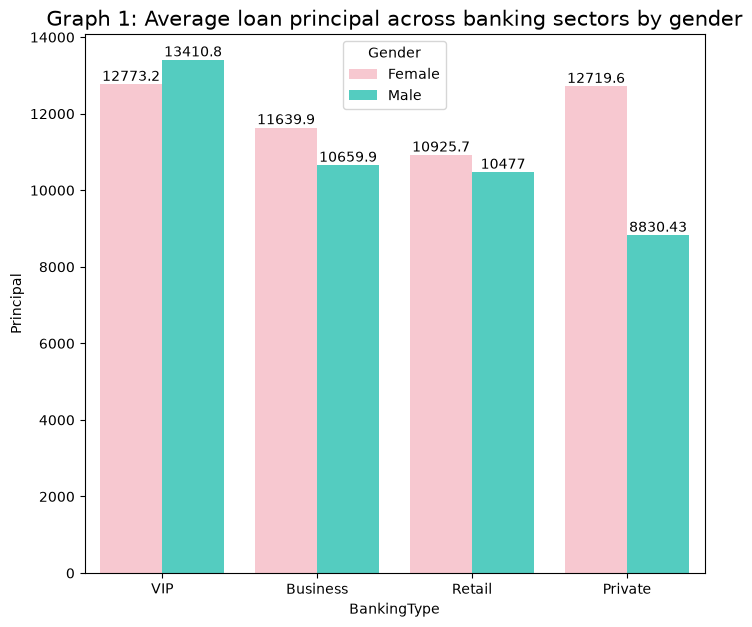

In [37]:
#.3.6 ויזואליזציה 
# גרף 1: השוואת סכום הקרן הממוצע של הלוואה בין סוגי הבנקאות לפי מגדר
dic={'Male':'turquoise', 'Female':'pink'}
plt.figure(figsize=(8,7))
a=sns.barplot(data=bl, x='BankingType', y='Principal', estimator='mean', hue='Gender', palette=dic, errorbar=None)
a.bar_label(a.containers[0])
a.bar_label(a.containers[1])
plt.title('Graph 1: Average loan principal across banking sectors by gender', fontsize=15)
plt.show()

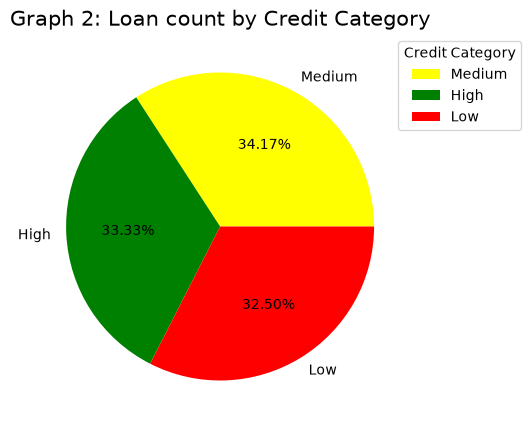

In [38]:
# גרף 2: התפלגות כמות ההלוואות לפי קטגוריית דירוג אשראי
counts=bl['CreditCategory'].value_counts().reset_index()
plt.figure(figsize=(5,5))
plt.pie(data=counts, x='count', labels='CreditCategory', autopct='%.2f%%', colors=['yellow','green','red'])
plt.title('Graph 2: Loan count by Credit Category', fontsize=15)
plt.legend(title="Credit Category", loc='upper right', bbox_to_anchor=(1.3, 1))
plt.show()

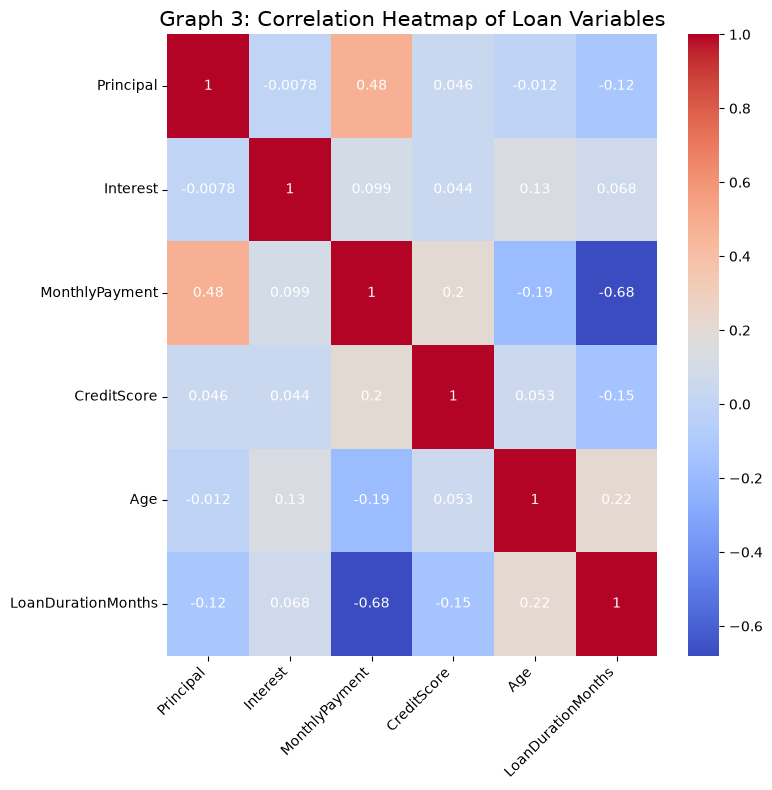

In [39]:
# גרף 3: מפת חום המציגה את המתאמים הליניאריים בין המשתנים הכמותיים הרלוונטים
plt.figure(figsize=(8,8))
columns=['Principal','Interest','MonthlyPayment','CreditScore','Age','LoanDurationMonths']
sns.heatmap(bl[columns].corr(), cmap='coolwarm', annot=True, annot_kws={'color': 'white'})
plt.title('Graph 3: Correlation Heatmap of Loan Variables', fontsize=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

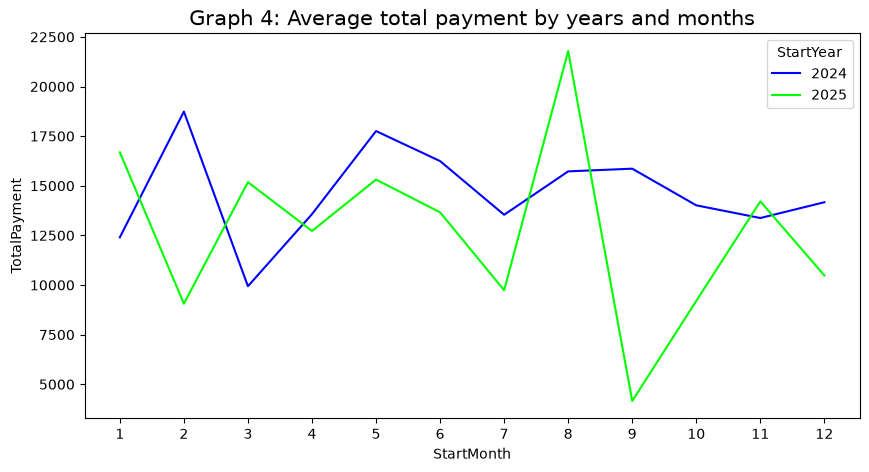

In [40]:
# גרף 4: ממוצע התשלום הכולל בהלוואה לפי שנים וחודשים
yearMonth=bl.groupby(['StartYear','StartMonth'])['TotalPayment'].mean().reset_index()
plt.figure(figsize=(10, 5))
sns.lineplot(data=yearMonth, x='StartMonth', y='TotalPayment', hue='StartYear', palette=['blue', 'lime'])
plt.title('Graph 4: Average total payment by years and months', fontsize=15)
plt.xticks(ticks=range(1, 13))
plt.show()

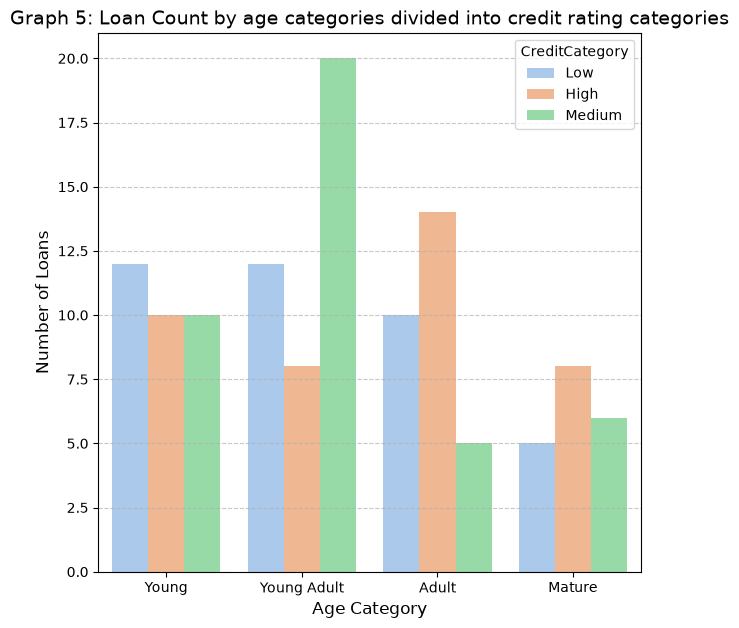

In [41]:
#גרף 5: התפלגות כמות הלוואות לפי קטגוריות גיל בחלוקה לקטגוריות דירוג אשראי
ageOrder=['Young','Young Adult','Adult','Mature']
plt.figure(figsize=(7, 7))
sns.countplot(data=bl, x='AgeCategory', hue='CreditCategory', order=ageOrder, palette='pastel')
plt.title('Graph 5: Loan Count by age categories divided into credit rating categories', fontsize=14)
plt.xlabel('Age Category', fontsize=12)
plt.ylabel('Number of Loans', fontsize=12)
plt.grid( axis='y', linestyle='--', alpha=0.7)
plt.show()

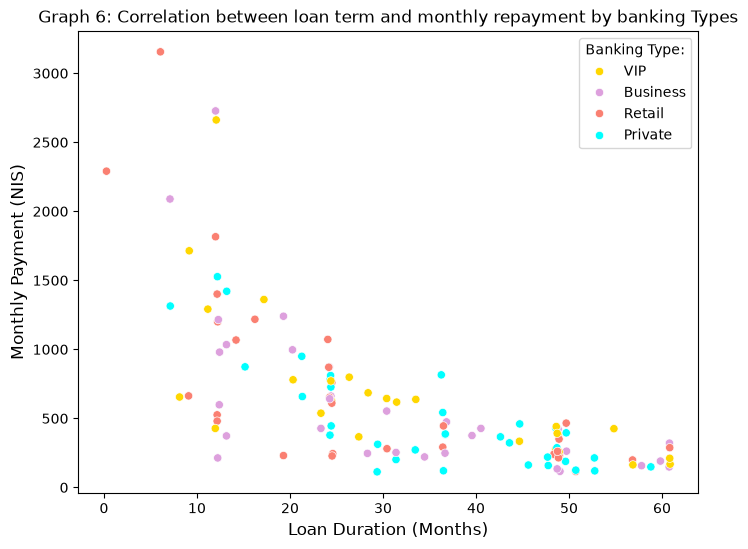

In [42]:
#גרף 6:  הקשר (מתאם) בין משך ההלוואה לבין ההחזר החודשי לפי סוגי הבנקאות
plt.figure(figsize=(8, 6))
p={'Business':'plum', 'Private':'aqua', 'Retail':'salmon', 'VIP':'gold'}
sns.scatterplot(data=bl,x='LoanDurationMonths', y='MonthlyPayment', hue='BankingType', palette= p)
plt.title('Graph 6: Correlation between loan term and monthly repayment by banking Types', fontsize=12)
plt.xlabel('Loan Duration (Months)',fontsize=12)
plt.ylabel('Monthly Payment (NIS)',fontsize=12)
plt.legend(title='Banking Type:', loc='upper right')
plt.show()